# SPARK-KYC — Set-membership Proofs with Anonymous Revocation and Keyed nullifiers
**A pairing-free, setup-free, unlinkable decentralized-KYC scheme with a learned AML predicate — reproducible Colab implementation**

Baseline: U. Arshad et al., *Web3-Based Identity and KYC Innovations for Next-Generation FinTech*, ACM TWEB 20(1), 2026 (DOI 10.1145/3771991).

| Stage | Baseline (Arshad et al.) | SPARK-KYC (this notebook) |
|---|---|---|
| Credential | VC = Sign(H(DID‖A)), full VC on IPFS, hash on chain | Pedersen vector commitment to 8 hidden attributes, holder secret blinded at issuance |
| Presentation | Per-user Groth16 (trusted setup), static DID | Re-randomised commitment + Groth–Kohlweiss one-out-of-many proof over an anonymity bucket of K (no trusted setup, no pairings) |
| Predicates | Selective disclosure (~20 % PII still revealed) | Age ≥ 18 and risk ≤ τ via bit-decomposition range proofs; sanctions = 0 via residual-generator elimination — **zero raw attributes revealed** |
| Sybil | Heuristic sigmoid score Ψ | Scope-keyed nullifier N = s·H(scope): exact double-registration detection, unlinkable across scopes |
| Revocation | Oracle write per credential | Drop from next epoch's buckets (O(1), no witness updates) |
| On-chain | One Groth16 verification per user | One root (+ nullifier calldata) per epoch — gas amortised over all users |
| AML risk | Fixed-weight linear formula, no dataset | Gradient-boosted trees on the **Elliptic** Bitcoin dataset (temporal split), quantised score committed and proven ≤ τ in ZK |

**How to run:** Runtime → Run all. No `pip install` needed. `MODE="FAST"` (default, ~10–15 min) or `"FULL"` (proves every one of the 1,000 users). All figures/tables are written to `results/`.

**Honesty notes for the paper.** (1) Crypto timings are *pure-Python* (CPython big-int) — native code is 1–2 orders of magnitude faster; report op counts alongside. (2) Gas numbers are from one transparent EIP-constant model applied to *both* systems, plus strengthened (batched/aggregated) Groth16 baselines; confirm at least one point on a local EVM before submission. (3) The baseline's own reported numbers are plotted as reported; its "35k–55k Gwei" mixes units (a Groth16 verify alone is ≥181k gas). (4) Anonymity is k-anonymity within a bucket of K, not the full user set.

## 0. Configuration

In [1]:
import os, sys, platform, multiprocessing as mp
MODE = os.environ.get("SPARK_MODE", "FAST")           # "FAST" (~10-15 min on free Colab) or "FULL" (paper-scale: proves every user; ~45-60 min)
CFG = dict(
    seeds=5 if MODE == "FULL" else 3,          # risk-model seeds (mean +- std)
    users=[100, 200, 400, 600, 800, 1000],     # same user loads as the baseline paper (Fig. 4/5)
    sample_per_load=5,   # proofs timed per user load (None = all users)
    K_values=[16, 32, 64, 128, 256],           # anonymity-set sizes for the K sweep
    K=64,                                      # default anonymity set
    concurrency=[10, 50, 100, 200, 500, 1000], # same concurrent loads as the baseline paper (Fig. 6)
    verifier_workers=8,                        # verifier server pool assumed in the latency model
    real_parallel_R=10,  # presentations actually verified in parallel to validate the model
    year_now=2026,
)
os.makedirs("results", exist_ok=True)
print(f"MODE={MODE} | Python {platform.python_version()} | CPU cores: {mp.cpu_count()}")

MODE=FAST | Python 3.12.0 | CPU cores: 12


## 1. Elliptic-curve arithmetic (BN254 / alt_bn128 G1)
Pure-Python Jacobian arithmetic, comb tables for fixed generators, Pippenger multi-scalar multiplication, and try-and-increment hash-to-curve for nothing-up-my-sleeve generators.

In [2]:
# Same curve as Ethereum's EIP-196/197/1108 precompiles, so every group operation
# used here has a known on-chain gas price (ECADD=150, ECMUL=6000).
import hashlib, os, secrets, time

P = 21888242871839275222246405745257275088696311157297823662689037894645226208583
R = 21888242871839275222246405745257275088548364400416034343698204186575808495617  # group order
B3 = 3                                    # y^2 = x^3 + 3
INF = None                                # point at infinity (Jacobian: None)

def _jdbl(Pt):
    if Pt is None: return None
    X, Y, Z = Pt
    if Y == 0: return None
    A = X * X % P; Bv = Y * Y % P; C = Bv * Bv % P
    D = 2 * ((X + Bv) ** 2 - A - C) % P
    E = 3 * A % P; F = E * E % P
    X3 = (F - 2 * D) % P
    Y3 = (E * (D - X3) - 8 * C) % P
    Z3 = 2 * Y * Z % P
    return (X3, Y3, Z3)

def _jadd(P1, P2):
    if P1 is None: return P2
    if P2 is None: return P1
    X1, Y1, Z1 = P1; X2, Y2, Z2 = P2
    Z1Z1 = Z1 * Z1 % P; Z2Z2 = Z2 * Z2 % P
    U1 = X1 * Z2Z2 % P; U2 = X2 * Z1Z1 % P
    S1 = Y1 * Z2 * Z2Z2 % P; S2 = Y2 * Z1 * Z1Z1 % P
    H = (U2 - U1) % P; rr = 2 * (S2 - S1) % P
    if H == 0:
        return _jdbl(P1) if rr == 0 else None
    I = (2 * H) ** 2 % P; J = H * I % P; V = U1 * I % P
    X3 = (rr * rr - J - 2 * V) % P
    Y3 = (rr * (V - X3) - 2 * S1 * J) % P
    Z3 = ((Z1 + Z2) ** 2 - Z1Z1 - Z2Z2) * H % P
    return (X3, Y3, Z3)

def _jneg(Pt):
    return None if Pt is None else (Pt[0], (-Pt[1]) % P, Pt[2])

def to_affine(Pt):
    if Pt is None: return None
    X, Y, Z = Pt
    zi = pow(Z, -1, P); zi2 = zi * zi % P
    return (X * zi2 % P, Y * zi2 * zi % P)

def from_affine(a):
    return None if a is None else (a[0], a[1], 1)

def on_curve(a):
    if a is None: return True
    x, y = a
    return (y * y - x * x * x - B3) % P == 0

def _jmul(Pt, k):
    """4-bit fixed-window scalar multiplication (variable base)."""
    k %= R
    if k == 0 or Pt is None: return None
    tbl = [None, Pt]
    for _ in range(14): tbl.append(_jadd(tbl[-1], Pt))
    acc = None
    for shift in range((k.bit_length() + 3) // 4 * 4 - 4, -1, -4):
        for _ in range(4): acc = _jdbl(acc)
        d = (k >> shift) & 15
        if d: acc = _jadd(acc, tbl[d])
    return acc

class Pt:
    """Immutable G1 element (stored affine). Supports +, -, scalar *."""
    __slots__ = ("a",)
    def __init__(self, a): self.a = a
    @staticmethod
    def J(j): return Pt(to_affine(j))
    def j(self): return from_affine(self.a)
    def __add__(self, o): return Pt.J(_jadd(self.j(), o.j()))
    def __sub__(self, o): return Pt.J(_jadd(self.j(), _jneg(o.j())))
    def __neg__(self): return Pt.J(_jneg(self.j()))
    def __mul__(self, k):
        fb = _FIXED.get(self.a)
        return Pt.J(fb.mul(k) if fb else _jmul(self.j(), k))
    __rmul__ = __mul__
    def __eq__(self, o): return isinstance(o, Pt) and self.a == o.a
    def __hash__(self): return hash(self.a)
    def is_inf(self): return self.a is None
    def to_bytes(self):            # 64-byte uncompressed (x||y), EVM precompile format
        if self.a is None: return b"\x00" * 64
        return self.a[0].to_bytes(32, "big") + self.a[1].to_bytes(32, "big")
    COMPRESSED_SIZE = 32           # x + 1 sign bit fits in 32 bytes since P < 2^254

ZERO = Pt(None)
G = Pt((1, 2))

class FixedBase:
    """Comb table for a fixed generator: k*P with 64 additions, no doublings."""
    def __init__(self, base_affine, w=4):
        self.w = w; self.tables = []
        cur = from_affine(base_affine)
        for _ in range((256 + w - 1) // w):
            row = [None]; acc = None
            for _d in range(1, 1 << w):
                acc = _jadd(acc, cur); row.append(acc)
            # normalise row to affine Jacobian (Z=1) for speed
            self.tables.append([None] + [from_affine(to_affine(x)) for x in row[1:]])
            for _ in range(w): cur = _jdbl(cur)
    def mul(self, k):
        k %= R; acc = None; i = 0; m = (1 << self.w) - 1
        while k:
            d = k & m
            if d: acc = _jadd(acc, self.tables[i][d])
            k >>= self.w; i += 1
        return acc

_FIXED = {}
def make_fixed(pt):
    if pt.a not in _FIXED: _FIXED[pt.a] = FixedBase(pt.a)
    return pt

def msm(points, scalars, c=None):
    """Pippenger bucket multi-scalar multiplication: sum_i s_i * P_i."""
    n = len(points)
    if n == 0: return ZERO
    if n < 8:
        acc = None
        for p_, s_ in zip(points, scalars): acc = _jadd(acc, (p_ * s_).j())
        return Pt.J(acc)
    if c is None: c = max(2, (n.bit_length() - 1) // 1 if n < 32 else n.bit_length() - 2)
    c = min(c, 12)
    js = [p_.j() for p_ in points]; sc = [s % R for s in scalars]
    nwin = (256 + c - 1) // c; total = None
    for wi in range(nwin - 1, -1, -1):
        for _ in range(c): total = _jdbl(total)
        buckets = [None] * (1 << c)
        sh = wi * c; mask = (1 << c) - 1
        for jp, s in zip(js, sc):
            d = (s >> sh) & mask
            if d: buckets[d] = _jadd(buckets[d], jp)
        run = None; acc = None
        for b in range(len(buckets) - 1, 0, -1):
            run = _jadd(run, buckets[b]); acc = _jadd(acc, run)
        total = _jadd(total, acc)
    return Pt.J(total)

def hash_to_curve(tag: bytes) -> Pt:
    """Try-and-increment (P = 3 mod 4). Nothing-up-my-sleeve generators: nobody
    knows their discrete logs, which Pedersen binding and GK15 soundness need."""
    ctr = 0
    while True:
        x = int.from_bytes(hashlib.sha256(tag + ctr.to_bytes(4, "big")).digest(), "big") % P
        rhs = (x * x * x + B3) % P
        y = pow(rhs, (P + 1) // 4, P)
        if y * y % P == rhs:
            if y & 1: y = P - y          # canonical even y
            return Pt((x, y))
        ctr += 1

def rand_scalar(): return secrets.randbelow(R - 1) + 1

def H2S(*parts) -> int:
    """Fiat-Shamir: SHA-512 over a typed transcript, reduced mod R (negligible bias)."""
    h = hashlib.sha512()
    for x in parts:
        if isinstance(x, Pt): b = x.to_bytes()
        elif isinstance(x, int): b = (x % (1 << 512)).to_bytes(64, "big")
        elif isinstance(x, str): b = x.encode()
        elif isinstance(x, (bytes, bytearray)): b = bytes(x)
        elif isinstance(x, (list, tuple)): b = H2S(*x).to_bytes(64, "big")
        else: raise TypeError(type(x))
        h.update(len(b).to_bytes(4, "big")); h.update(b)
    return int.from_bytes(h.digest(), "big") % R

# quick self-test
assert on_curve(G.a) and (G * R).is_inf() and (G * 5 - G * 2) == G * 3
print("BN254 G1 ready; generator on curve, order check passed.")

BN254 G1 ready; generator on curve, order check passed.


## 2. Zero-knowledge building blocks
* **CDS OR-proof** that a committed bit is 0 or 1.
* **Representation proof** for the residual commitment, linked to the nullifier through the shared secret *s*.
* **Groth–Kohlweiss one-out-of-many proof**: one of K commitments opens to 0 — proof size O(log K), verifier does two MSMs.

In [3]:
#   (a) bit OR-proof          b in {0,1} for B = b*Gj + t*H                 [CDS'94]
#   (b) representation proof  R = sum x_i*G_i  AND  N = x_0*P_scope (nullifier link)
#   (c) one-out-of-many proof one of D_0..D_{K-1} opens to 0 (log-size)     [Groth-Kohlweiss EC'15]
SCALAR = 32; POINT = Pt.COMPRESSED_SIZE   # bytes, for proof-size accounting

# ---------- (a) bit proofs -------------------------------------------------
# Proof = (c0, c1, z0, z1); verifier recomputes A0, A1 and checks c0 + c1 = H(...)
def bit_prove(b, t, Gj, Hg, ctx):
    Bc = Gj * b + Hg * t
    w = rand_scalar(); c_o = rand_scalar(); z_o = rand_scalar(); o = 1 - b
    A = [None, None]
    A[b] = Hg * w
    A[o] = Hg * z_o - (Bc - Gj * o) * c_o
    c = H2S("bit", ctx, Bc, A[0], A[1])
    c_b = (c - c_o) % R; z_b = (w + c_b * t) % R
    cs = [0, 0]; zs = [0, 0]; cs[b], cs[o] = c_b, c_o; zs[b], zs[o] = z_b, z_o
    return Bc, (cs[0], cs[1], zs[0], zs[1])

def bit_verify(Bc, pr, Gj, Hg, ctx):
    c0, c1, z0, z1 = pr
    A0 = Hg * z0 - Bc * c0
    A1 = Hg * z1 - (Bc - Gj) * c1
    return (c0 + c1) % R == H2S("bit", ctx, Bc, A0, A1)

# ---------- (b) representation proof with nullifier link --------------------
def rep_prove(xs, gens, Rpt, s_idx, Pscope, Nul, ctx):
    ws = [rand_scalar() for _ in xs]
    A = msm(gens, ws); AN = Pscope * ws[s_idx]
    c = H2S("rep", ctx, Rpt, Nul, A, AN)
    zs = [(w + c * x) % R for w, x in zip(ws, xs)]
    return (c, zs)

def rep_verify(pr, gens, Rpt, s_idx, Pscope, Nul, ctx):
    c, zs = pr
    A = msm(list(gens) + [Rpt], list(zs) + [(-c) % R])
    AN = Pscope * zs[s_idx] - Nul * c
    return c == H2S("rep", ctx, Rpt, Nul, A, AN)

# ---------- (c) Groth-Kohlweiss one-out-of-many proof -----------------------
def _poly_mul(a, b):
    out = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        if x:
            for j, y in enumerate(b): out[i + j] = (out[i + j] + x * y) % R
    return out

def oom_prove(D, l, rho, U, Hg, ctx):
    """Prove knowledge of l, rho such that D[l] = rho*Hg, with |D| = 2^m. Size O(log K)."""
    K = len(D); m = K.bit_length() - 1; assert 1 << m == K
    lb = [(l >> j) & 1 for j in range(m)]
    r_ = [rand_scalar() for _ in range(m)]; a_ = [rand_scalar() for _ in range(m)]
    s_ = [rand_scalar() for _ in range(m)]; t_ = [rand_scalar() for _ in range(m)]
    rk = [rand_scalar() for _ in range(m)]
    cl = [U * lb[j] + Hg * r_[j] for j in range(m)]
    ca = [U * a_[j] + Hg * s_[j] for j in range(m)]
    cb = [U * (lb[j] * a_[j]) + Hg * t_[j] for j in range(m)]
    # coefficients p_{i,k}: p_i(x) = prod_j f_{j,i_j}(x)
    f1 = [[a_[j], lb[j]] for j in range(m)]                 # l_j x + a_j
    f0 = [[(-a_[j]) % R, (1 - lb[j]) % R] for j in range(m)]  # (1-l_j) x - a_j
    coeffs = []
    for i in range(K):
        p = [1]
        for j in range(m): p = _poly_mul(p, f1[j] if (i >> j) & 1 else f0[j])
        coeffs.append(p)
    cd = []
    for k in range(m):
        cd.append(msm(list(D) + [Hg], [coeffs[i][k] for i in range(K)] + [rk[k]]))
    x = H2S("oom", ctx, list(D), cl, ca, cb, cd)
    f = [(lb[j] * x + a_[j]) % R for j in range(m)]
    za = [(r_[j] * x + s_[j]) % R for j in range(m)]
    zb = [(r_[j] * (x - f[j]) + t_[j]) % R for j in range(m)]
    zd = (rho * pow(x, m, R) - sum(rk[k] * pow(x, k, R) for k in range(m))) % R
    return (cl, ca, cb, cd, f, za, zb, zd)

def oom_verify(D, pr, U, Hg, ctx):
    cl, ca, cb, cd, f, za, zb, zd = pr
    K = len(D); m = K.bit_length() - 1
    if not all(len(v) == m for v in (cl, ca, cb, cd, f, za, zb)): return False
    x = H2S("oom", ctx, list(D), cl, ca, cb, cd)
    rnd = [rand_scalar() for _ in range(2 * m)]     # batch the 2m small checks into one MSM
    pts, scs = [], []
    for j in range(m):
        # x*cl + ca - f*U - za*H == 0
        e = rnd[j]
        pts += [cl[j], ca[j], U, Hg]; scs += [x * e, e, -f[j] * e, -za[j] * e]
        # (x-f)*cl + cb - zb*H == 0
        e = rnd[m + j]
        pts += [cl[j], cb[j], Hg]; scs += [(x - f[j]) * e, e, -zb[j] * e]
    if not msm(pts, [s % R for s in scs]).is_inf(): return False
    # sum_i (prod_j f_{j,i_j}) D_i - sum_k x^k cd_k - zd*H == 0
    fv = [[(x - f[j]) % R, f[j]] for j in range(m)]
    sc = []
    for i in range(K):
        v = 1
        for j in range(m): v = v * fv[j][(i >> j) & 1] % R
        sc.append(v)
    pts = list(D) + list(cd) + [Hg]
    scs = sc + [(-pow(x, k, R)) % R for k in range(m)] + [(-zd) % R]
    return msm(pts, scs).is_inf()

def oom_size(K):
    m = K.bit_length() - 1
    return 4 * m * POINT + (3 * m + 1) * SCALAR
print("ZK building blocks loaded.")

ZK building blocks loaded.


## 3. SPARK-KYC protocol
`Issuer` (blind issuance, buckets, epochs, revocation) · `Holder` · `present()` · `Verifier` (nullifier set per scope). Policy = list of predicates; it is bound into the Fiat–Shamir transcript together with scope, nonce, epoch root and bucket id (replay protection).

In [4]:
ATTRS = ["secret", "birth_year", "sanctioned", "risk", "nationality",
         "name_h", "addr_h", "docid_h"]                       # 8 hidden attributes
IDX = {a: i for i, a in enumerate(ATTRS)}
GENS = [make_fixed(hash_to_curve(b"SPARK-KYC/G/" + a.encode())) for a in ATTRS]
Hg = make_fixed(hash_to_curve(b"SPARK-KYC/H"))
U = make_fixed(hash_to_curve(b"SPARK-KYC/U"))               # GK15 value generator

def h_attr(s: str) -> int:  # hash a PII string into a scalar (never revealed)
    return int.from_bytes(hashlib.sha256(s.encode()).digest(), "big") % R

def scope_point(scope: str) -> Pt:
    return hash_to_curve(b"SPARK-KYC/scope/" + scope.encode())

class Issuer:
    """KYC provider. Registry = list of buckets (anonymity sets) of size K per epoch."""
    def __init__(self, K=64):
        self.K = K; self.creds = []; self.revoked = set(); self.epoch = 0
        self.seen_docs = set(); self._build()
    def issue(self, holder_S, holder_pok, attrs: dict):
        # holder_S = s*G_secret + r_h*H, with PoK (issuer never learns s)
        c, z1, z2 = holder_pok
        A = GENS[0] * z1 + Hg * z2 - holder_S * c
        assert c == H2S("issue-pok", holder_S, A), "bad holder PoK"
        if attrs["docid_h"] in self.seen_docs: raise ValueError("duplicate identity document")
        self.seen_docs.add(attrs["docid_h"])
        r_i = rand_scalar()
        C = holder_S + msm(GENS[1:], [attrs[a] for a in ATTRS[1:]]) + Hg * r_i
        self.creds.append(C)
        return len(self.creds) - 1, r_i
    def revoke(self, cid): self.revoked.add(cid)
    def _build(self):
        """New epoch: active credentials, padded with random dummy points, split into
        buckets of K. Revocation = simply not including the credential (O(1), no witnesses)."""
        act = [i for i in range(len(self.creds)) if i not in self.revoked]
        self.slot = {}; self.buckets = []
        for b0 in range(0, max(len(act), 1), self.K):
            ids = act[b0:b0 + self.K]
            pts = [self.creds[i] for i in ids]
            while len(pts) < self.K: pts.append(hash_to_curve(b"pad%d/%d" % (self.epoch, len(pts) + b0)))
            for pos, i in enumerate(ids): self.slot[i] = (len(self.buckets), pos)
            self.buckets.append(pts)
        self.root = hashlib.sha256(b"".join(p.to_bytes() for bk in self.buckets for p in bk)).hexdigest()
    def new_epoch(self): self.epoch += 1; self._build()

class Holder:
    def __init__(self, attrs_public_part: dict):
        self.s = rand_scalar(); self.r_h = rand_scalar(); self.attrs = dict(attrs_public_part)
        self.attrs["secret"] = self.s
    def request(self):
        S = GENS[0] * self.s + Hg * self.r_h
        w1, w2 = rand_scalar(), rand_scalar()
        c = H2S("issue-pok", S, GENS[0] * w1 + Hg * w2)
        return S, (c, (w1 + c * self.s) % R, (w2 + c * self.r_h) % R)
    def store(self, cid, r_i): self.cid = cid; self.r = (self.r_h + r_i) % R

# ----- a verifier policy: which predicates must hold ------------------------
# ("ge", attr, lo, nbits): attr >= lo ; ("le", attr, hi, nbits): attr <= hi ; ("eq", attr, value)
def default_policy(year_now=2026, tau=50):
    return [("le", "birth_year", year_now - 18, 7),   # age >= 18  <=> birth_year <= now-18
            ("le", "risk", tau, 7),                     # AML risk score <= tau (0..100)
            ("eq", "sanctioned", 0)]                     # not on a sanctions list

def present(holder, issuer, policy, scope, nonce):
    b, pos = issuer.slot[holder.cid]
    bucket = issuer.buckets[b]
    ctx = [scope, nonce, issuer.root, b, repr(policy)]
    a = holder.attrs
    rho = rand_scalar()
    Cs = issuer.creds[holder.cid] - Hg * rho                 # re-randomised commitment
    r_star = (holder.r - rho) % R
    D = [Ci - Cs for Ci in bucket]
    oom = oom_prove(D, pos, rho, U, Hg, ctx + [Cs])
    # predicates
    resid_r = r_star; used = set(); bitproofs = []
    for pr in policy:
        kind, name = pr[0], pr[1]; j = IDX[name]; used.add(j)
        if kind == "eq":
            assert a[name] == pr[2], "policy not satisfied"; continue
        bound, nb = pr[2], pr[3]
        v = (a[name] - bound) if kind == "ge" else (bound - a[name])
        assert 0 <= v < (1 << nb), "policy not satisfied"
        bits = []
        for k in range(nb):
            bk = (v >> k) & 1; tk = rand_scalar()
            Bc, p_ = bit_prove(bk, tk, GENS[j], Hg, ctx + [Cs, name, k])
            bits.append((Bc, p_))
            resid_r = (resid_r - (1 << k) * tk) % R if kind == "ge" else (resid_r + (1 << k) * tk) % R
        bitproofs.append(bits)
    free = [j for j in range(len(ATTRS)) if j not in used]
    gens = [GENS[j] for j in free] + [Hg]
    xs = [a[ATTRS[j]] for j in free] + [resid_r]
    Ps = scope_point(scope); Nul = Ps * a["secret"]
    Rpt = residual(Cs, policy, bitproofs)
    rep = rep_prove(xs, gens, Rpt, free.index(0), Ps, Nul, ctx + [Cs])
    return dict(bucket=b, Cs=Cs, oom=oom, bits=bitproofs, rep=rep, nullifier=Nul)

def residual(Cs, policy, bitproofs):
    Rpt = Cs; bi = 0
    for pr in policy:
        kind, name = pr[0], pr[1]; Gj = GENS[IDX[name]]
        if kind == "eq": Rpt = Rpt - Gj * pr[2]; continue
        Sbits = msm([Bc for Bc, _ in bitproofs[bi]], [1 << k for k in range(len(bitproofs[bi]))])
        Rpt = Rpt - Gj * pr[2] - Sbits if kind == "ge" else Rpt - Gj * pr[2] + Sbits
        bi += 1
    return Rpt

class Verifier:
    """Relying party (bank / DeFi front-end). Keeps the nullifier set for its scope."""
    def __init__(self, scope, policy): self.scope = scope; self.policy = policy; self.nullifiers = set()
    def verify(self, pres, issuer, nonce, register=True):
        b = pres["bucket"]; ctx = [self.scope, nonce, issuer.root, b, repr(self.policy)]; Cs = pres["Cs"]
        if b >= len(issuer.buckets): return False, "unknown bucket"
        D = [Ci - Cs for Ci in issuer.buckets[b]]
        if not oom_verify(D, pres["oom"], U, Hg, ctx + [Cs]): return False, "not a current credential"
        bi = 0; used = set()
        for pr in self.policy:
            used.add(IDX[pr[1]])
            if pr[0] == "eq": continue
            bits = pres["bits"][bi]; bi += 1
            if len(bits) != pr[3]: return False, "range length"
            for k, (Bc, p_) in enumerate(bits):
                if not bit_verify(Bc, p_, GENS[IDX[pr[1]]], Hg, ctx + [Cs, pr[1], k]): return False, "predicate"
        free = [j for j in range(len(ATTRS)) if j not in used]
        gens = [GENS[j] for j in free] + [Hg]
        Rpt = residual(Cs, self.policy, pres["bits"])
        if not rep_verify(pres["rep"], gens, Rpt, free.index(0), scope_point(self.scope), pres["nullifier"], ctx + [Cs]):
            return False, "representation/nullifier"
        nk = pres["nullifier"].to_bytes()
        if nk in self.nullifiers: return False, "sybil: nullifier reused"
        if register: self.nullifiers.add(nk)
        return True, "ok"

def proof_size(pres):
    n = POINT + oom_size(len(pres["oom"][0]) and (1 << len(pres["oom"][0])))
    n += sum(len(bits) * (POINT + 4 * SCALAR) for bits in pres["bits"])
    n += (1 + len(pres["rep"][1])) * SCALAR + POINT + 2       # rep proof + nullifier + bucket id
    return n
print("SPARK-KYC protocol loaded.")

SPARK-KYC protocol loaded.


## 3b. Correctness and soundness checks
Valid proof accepted; replay, wrong nonce, tampered commitment, revoked credential, stale epoch, lying holder and policy-violating holders all rejected.

In [5]:
import time
iss=Issuer(K=64); hs=[]
for i in range(70):
    h=Holder(dict(birth_year=1980+i%30, sanctioned=1 if i==5 else 0, risk=10+i%60, nationality=356,
                  name_h=h_attr('n%d'%i), addr_h=h_attr('a%d'%i), docid_h=h_attr('d%d'%i)))
    S,pok=h.request(); cid,ri=iss.issue(S,pok,h.attrs); h.store(cid,ri); hs.append(h)
iss.new_epoch()
pol=default_policy(tau=50); v=Verifier('bankA',pol)
t=time.time(); pr=present(hs[0],iss,pol,'bankA','n1'); tp=time.time()-t
t=time.time(); ok=v.verify(pr,iss,'n1'); tv=time.time()-t
print('valid',ok,'prove %.3fs verify %.3fs size %dB'%(tp,tv,proof_size(pr)))
print('replay same holder:',v.verify(present(hs[0],iss,pol,'bankA','n2'),iss,'n2'))
v2=Verifier('bankB',pol); pr2=present(hs[0],iss,pol,'bankB','n3'); print('other scope', v2.verify(pr2,iss,'n3'), 'nullifiers differ', pr2['nullifier']!=pr['nullifier'])
print('wrong nonce:', Verifier('bankA',pol).verify(pr,iss,'other'))
# tamper: change Cs
import copy; bad=dict(pr); bad['Cs']=pr['Cs']+GENS[IDX['risk']]*(-30)
print('tampered Cs:', Verifier('bankA',pol).verify(bad,iss,'n1'))
# failing predicates
for i,why in [(5,'sanctioned'),(45,'risk 55>50')]:
    try: present(hs[i],iss,pol,'x','y'); print('ERROR no assert',why)
    except AssertionError: print('holder cannot prove:',why)
# young
try: present(hs[29] if hs[29].attrs['birth_year']>2008 else hs[0],iss,[("le","birth_year",1990,7)],'x','y'); print('ok proved by<=1990 for',hs[0].attrs['birth_year'])
except AssertionError: print('young assert')
# revocation
iss.revoke(hs[1].cid); iss.new_epoch()
try: present(hs[1],iss,pol,'bankA','n9'); print('ERROR revoked presented')
except KeyError: print('revoked holder has no slot in new epoch')
# stale proof against new epoch root
print('old proof after epoch change:', Verifier('bankC',pol).verify(pr,iss,'n1'))
# forged: holder lies risk attribute (claims 20) but committed 55
h=hs[45]; h.attrs['risk']=20
print('lying holder:', Verifier('bankD',pol).verify(present(h,iss,pol,'bankD','z'),iss,'z'))

valid (True, 'ok') prove 0.158s verify 0.095s size 3906B


replay same holder: (False, 'sybil: nullifier reused')
other scope (True, 'ok') nullifiers differ True


wrong nonce: (False, 'not a current credential')
tampered Cs: (False, 'not a current credential')
holder cannot prove: sanctioned


holder cannot prove: risk 55>50
young assert
revoked holder has no slot in new epoch
old proof after epoch change: (False, 'not a current credential')


lying holder: (False, 'representation/nullifier')


## 4. Datasets
* **Elliptic Bitcoin dataset** (Weber et al., 2019): 203,769 transactions, 46,564 labelled, 165 features, 49 time steps — downloaded from the same no-login mirror PyTorch-Geometric uses. Standard temporal split: train t = 1–34, test t = 35–49.
* **1,000 synthetic KYC users** — the baseline paper's evaluation scale — each bound to one held-out Elliptic entity so its risk score and ground-truth label are real.

In [6]:
import io, zipfile, urllib.request, numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score, roc_auc_score

DATA_DIR = "elliptic"; os.makedirs(DATA_DIR, exist_ok=True)
URL = "https://data.pyg.org/datasets/elliptic/{}.zip"     # same source torch_geometric uses (no login)

def load_elliptic():
    frames = {}
    for name in ["elliptic_txs_features.csv", "elliptic_txs_classes.csv"]:
        path = os.path.join(DATA_DIR, name)
        if not os.path.exists(path):
            print("downloading", name, "...")
            raw = urllib.request.urlopen(URL.format(name), timeout=120).read()
            zipfile.ZipFile(io.BytesIO(raw)).extractall(DATA_DIR)
        frames[name] = path
    X = pd.read_csv(frames["elliptic_txs_features.csv"], header=None)
    X.columns = ["txId", "ts"] + [f"f{i}" for i in range(X.shape[1] - 2)]
    y = pd.read_csv(frames["elliptic_txs_classes.csv"])
    df = X.merge(y, on="txId")
    df = df[df["class"].astype(str) != "unknown"].copy()
    df["y"] = (df["class"].astype(str) == "1").astype(int)       # 1 = illicit
    return df, True

def synthetic_elliptic_like(seed=0):
    """Fallback ONLY if the download is blocked; NOT for reporting results."""
    rng = np.random.default_rng(seed); n = 46564
    ts = rng.integers(1, 50, n); y = (rng.random(n) < 0.098).astype(int)
    F = rng.normal(size=(n, 165)) + y[:, None] * rng.normal(0.4, 0.3, 165)
    df = pd.DataFrame(F, columns=[f"f{i}" for i in range(165)]); df["ts"] = ts; df["y"] = y
    return df, False

try:
    ell, REAL_DATA = load_elliptic()
except Exception as e:
    print("!! Elliptic download failed:", repr(e)[:120], "-> using synthetic stand-in (do not report)")
    ell, REAL_DATA = synthetic_elliptic_like()
feat = [c for c in ell.columns if c.startswith("f")]
train = ell[ell.ts <= 34]; test = ell[ell.ts >= 35]               # standard temporal split (Weber et al. 2019)
print(f"Elliptic labelled txs: {len(ell):,} | train {len(train):,} | test {len(test):,} | "
      f"illicit share {ell.y.mean():.3f} | real data: {REAL_DATA}")

Elliptic labelled txs: 46,564 | train 29,894 | test 16,670 | illicit share 0.098 | real data: True


## 5. AML risk model
Generous baseline: the paper's linear Eq. 15 is given *learned* weights (logistic regression on all 165 features). SPARK-KYC uses GBDT; RF reported for reference against Weber et al. (illicit F1 ≈ 0.79). τ is tuned on t = 29–34 and frozen before testing; scores are quantised to 0–100 exactly as committed in the credential.

In [7]:
# Baseline (Arshad et al., Eq. 15): a LINEAR score R = w1*Htx + w2*Sip + w3*Fhist with hand-set weights and no
# dataset. To be generous to the baseline we give it LEARNED linear weights over all 165 features (logistic
# regression), which can only do better than hand-set weights. SPARK-KYC uses gradient-boosted trees.
# Score is quantised to an integer 0..100 (what the issuer commits); tau is tuned on a validation slice
# (time steps 29-34) and frozen before touching the test split (35-49).
def quantise(p): return np.clip(np.rint(100 * p), 0, 100).astype(int)

def fit_model(kind, Xtr, ytr, seed):
    if kind == "linear":
        sc = StandardScaler().fit(Xtr)
        m = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced", random_state=seed).fit(sc.transform(Xtr), ytr)
        return lambda X: m.predict_proba(sc.transform(X))[:, 1]
    if kind == "gbdt":
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                           l2_regularization=1.0, random_state=seed).fit(Xtr, ytr)
        return lambda X: m.predict_proba(X)[:, 1]
    if kind == "rf":
        m = RandomForestClassifier(n_estimators=50, max_features=50, n_jobs=-1, random_state=seed).fit(Xtr, ytr)   # Weber et al. 2019 setting
        return lambda X: m.predict_proba(X)[:, 1]

def best_tau(score, y):
    best = (0, -1)
    for t in range(0, 101):
        f = f1_score(y, (score > t).astype(int), zero_division=0)
        if f > best[1]: best = (t, f)
    return best[0]

def evaluate(kind, seed):
    t0 = time.perf_counter()
    fit_tr = train[train.ts <= 28]; val = train[train.ts >= 29]
    f_val = fit_model(kind, fit_tr[feat].values, fit_tr.y.values, seed)
    sv = quantise(f_val(val[feat].values)); tau = best_tau(sv, val.y.values)
    val_f1 = f1_score(val.y.values, (sv > tau).astype(int))
    f = fit_model(kind, train[feat].values, train.y.values, seed)
    s = quantise(f(test[feat].values)); yhat = (s > tau).astype(int); y = test.y.values
    pre = (test.ts < 43).values                              # dark-market shutdown at t=43
    return dict(model=kind, seed=seed, tau=tau, val_F1=val_f1,
                illicit_F1=f1_score(y, yhat), precision=precision_score(y, yhat, zero_division=0),
                recall=recall_score(y, yhat), PR_AUC=average_precision_score(y, s), ROC_AUC=roc_auc_score(y, s),
                F1_before_t43=f1_score(y[pre], yhat[pre]), F1_after_t43=f1_score(y[~pre], yhat[~pre], zero_division=0), fit_s=time.perf_counter() - t0), f, tau

risk_rows = []; MODELS = {}
for kind in ["linear", "gbdt", "rf"]:
    for seed in range(CFG["seeds"] if (kind != "rf" or MODE == "FULL") else 1):   # RF is slow on 2-core Colab
        row, f, tau = evaluate(kind, seed); risk_rows.append(row); print(f'  {kind} seed {seed}: illicit F1 {row["illicit_F1"]:.3f} ({row["fit_s"]:.0f}s)', flush=True)
        if seed == 0: MODELS[kind] = (f, tau)
risk_df = pd.DataFrame(risk_rows)
risk_summary = risk_df.groupby("model").agg(["mean", "std"]).drop(columns="seed").round(4)
display_cols = ["illicit_F1", "precision", "recall", "PR_AUC", "ROC_AUC", "F1_before_t43", "F1_after_t43", "tau"]
print(risk_summary[display_cols].to_string())
risk_df.to_csv("results/risk_models_per_seed.csv", index=False)
# SPARK issuer model = the tree ensemble with the higher VALIDATION F1 (chosen without looking at the test split)
SPARK_MODEL = risk_df[risk_df.model != "linear"].groupby("model").val_F1.mean().idxmax()
SCORER, TAU = MODELS[SPARK_MODEL]
LIN_SCORER, LIN_TAU = MODELS["linear"]
print(f"SPARK-KYC issuer model (selected on validation): {SPARK_MODEL}, frozen tau = {TAU}")

  linear seed 0: illicit F1 0.360 (3s)


  linear seed 1: illicit F1 0.360 (3s)


  linear seed 2: illicit F1 0.360 (3s)


  gbdt seed 0: illicit F1 0.804 (7s)


  gbdt seed 1: illicit F1 0.798 (6s)


  gbdt seed 2: illicit F1 0.776 (8s)


  rf seed 0: illicit F1 0.794 (5s)


       illicit_F1         precision          recall          PR_AUC         ROC_AUC         F1_before_t43         F1_after_t43              tau         
             mean     std      mean     std    mean     std    mean     std    mean     std          mean     std         mean     std     mean      std
model                                                                                                                                                   
gbdt       0.7927  0.0146    0.8696  0.0439  0.7291  0.0068  0.7727  0.0014  0.8824  0.0013        0.8951  0.0062       0.0305  0.0057  33.3333  10.5987
linear     0.3597  0.0000    0.2441  0.0000  0.6833  0.0000  0.2877  0.0000  0.8785  0.0000        0.4882  0.0000       0.0724  0.0000  84.0000   0.0000
rf         0.7937     NaN    0.8771     NaN  0.7248     NaN  0.7834     NaN  0.9159     NaN        0.8947     NaN       0.0261     NaN  46.0000      NaN
SPARK-KYC issuer model (selected on validation): rf, frozen tau = 46


## 6. Experiments
E1 cost vs users (paper Fig. 4/5) · E2 cost vs anonymity set K · E3 gas per user (paper Fig. 4 right, Table 3) · E4 latency vs concurrent requests (paper Fig. 6), validated with a real parallel run · E5 privacy / linkability / Sybil / revocation / KYC decisions (paper Eq. 31, Fig. 8).

In [8]:
rng = np.random.default_rng(42)
N_MAX = max(CFG["users"])
idx = rng.choice(len(test), N_MAX, replace=False)          # each user = one held-out Elliptic entity
users = pd.DataFrame({
    "birth_year": rng.integers(1940, 2012, N_MAX),            # ~ 8% minors in 2026
    "sanctioned": (rng.random(N_MAX) < 0.02).astype(int),
    "nationality": rng.integers(1, 250, N_MAX),
    "illicit": test.y.values[idx],
})
users["risk_spark"] = quantise(SCORER(test[feat].values[idx]))
users["risk_linear"] = quantise(LIN_SCORER(test[feat].values[idx]))
pol = default_policy(CFG["year_now"], TAU)
users["eligible"] = ((users.birth_year <= CFG["year_now"] - 18) & (users.sanctioned == 0) & (users.risk_spark <= TAU))
print(users.describe().loc[["mean"]].round(3).to_string())

def onboard(n, K, risk_col="risk_spark"):
    iss = Issuer(K=K); hs = []
    for i in range(n):
        u = users.iloc[i]
        h = Holder(dict(birth_year=int(u.birth_year), sanctioned=int(u.sanctioned), risk=int(u[risk_col]),
                        nationality=int(u.nationality), name_h=h_attr(f"name{i}"), addr_h=h_attr(f"addr{i}"),
                        docid_h=h_attr(f"doc{i}")))
        S, pok = h.request(); cid, ri = iss.issue(S, pok, h.attrs); h.store(cid, ri); hs.append(h)
    iss.new_epoch()
    return iss, hs

      birth_year  sanctioned  nationality  illicit  risk_spark  risk_linear
mean    1975.264       0.013      122.213    0.059      10.352       29.619


In [9]:
def time_presentations(iss, hs, ids, scope="bank"):
    v = Verifier(scope, pol); tp, tv, sz, oks = [], [], [], 0
    for i in ids:
        t0 = time.perf_counter(); pr = present(hs[i], iss, pol, scope, f"nonce{i}"); t1 = time.perf_counter()
        ok, _ = v.verify(pr, iss, f"nonce{i}"); t2 = time.perf_counter()
        tp.append(t1 - t0); tv.append(t2 - t1); sz.append(proof_size(pr)); oks += ok
    return np.array(tp), np.array(tv), np.array(sz), oks

rows_N = []
iss_all, hs_all = onboard(N_MAX, CFG["K"])
for n in CFG["users"]:
    t0 = time.perf_counter(); iss_n, hs_n = onboard(n, CFG["K"]); t_onb = time.perf_counter() - t0
    elig = [i for i in range(n) if users.eligible.iloc[i]]
    ids = elig if CFG["sample_per_load"] is None else list(rng.choice(elig, min(CFG["sample_per_load"], len(elig)), replace=False))
    tp, tv, sz, oks = time_presentations(iss_n, hs_n, ids)
    rows_N.append(dict(users=n, prove_ms=1e3 * tp.mean(), prove_sd=1e3 * tp.std(), verify_ms=1e3 * tv.mean(),
                       verify_sd=1e3 * tv.std(), proof_bytes=int(sz.mean()), all_valid=(oks == len(ids)),
                       issuance_ms_per_user=1e3 * t_onb / n, timed=len(ids)))
    print(rows_N[-1])
res_N = pd.DataFrame(rows_N); res_N.to_csv("results/E1_cost_vs_users.csv", index=False)

rows_K = []
for K in CFG["K_values"]:
    iss_k, hs_k = onboard(max(K, 128), K)
    elig = [i for i in range(len(hs_k)) if users.eligible.iloc[i]][:15]
    tp, tv, sz, oks = time_presentations(iss_k, hs_k, elig)
    rows_K.append(dict(K=K, prove_ms=1e3 * tp.mean(), verify_ms=1e3 * tv.mean(), proof_bytes=int(sz.mean()), all_valid=oks == len(elig)))
    print(rows_K[-1])
res_K = pd.DataFrame(rows_K); res_K.to_csv("results/E2_cost_vs_anonymity_set.csv", index=False)

{'users': 100, 'prove_ms': 168.41536001302302, 'prove_sd': 1.9950505170657722, 'verify_ms': 99.45265999995172, 'verify_sd': 1.0855580501991413, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.85435500042513, 'timed': 5}


{'users': 200, 'prove_ms': 169.8288000188768, 'prove_sd': 1.5054660768674917, 'verify_ms': 99.04033998027444, 'verify_sd': 1.9097252170554082, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.7071384999435395, 'timed': 5}


{'users': 400, 'prove_ms': 171.23131998814642, 'prove_sd': 1.3692563017981736, 'verify_ms': 100.59993998147547, 'verify_sd': 0.8965613570931962, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.7091727500082925, 'timed': 5}


{'users': 600, 'prove_ms': 166.52395999990404, 'prove_sd': 3.3877684286275405, 'verify_ms': 98.9519199822098, 'verify_sd': 1.132131955130859, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.6571880000798656, 'timed': 5}


{'users': 800, 'prove_ms': 166.9366200454533, 'prove_sd': 2.1087594366649776, 'verify_ms': 98.74815996736288, 'verify_sd': 0.793229410228369, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.575553500035312, 'timed': 5}


{'users': 1000, 'prove_ms': 164.9108599871397, 'prove_sd': 3.894976383832269, 'verify_ms': 98.6381999682635, 'verify_sd': 1.2487444382370378, 'proof_bytes': 3906, 'all_valid': True, 'issuance_ms_per_user': 4.551376699935645, 'timed': 5}


{'K': 16, 'prove_ms': 81.46025332001348, 'verify_ms': 81.68106001491347, 'proof_bytes': 3458, 'all_valid': True}


{'K': 32, 'prove_ms': 106.83612666713695, 'verify_ms': 84.52649336929123, 'proof_bytes': 3682, 'all_valid': True}


{'K': 64, 'prove_ms': 167.35389336633185, 'verify_ms': 98.12013998938103, 'proof_bytes': 3906, 'all_valid': True}


{'K': 128, 'prove_ms': 280.95722665699816, 'verify_ms': 119.59759998135269, 'proof_bytes': 4130, 'all_valid': True}


{'K': 256, 'prove_ms': 501.5815200128902, 'verify_ms': 154.96232000490028, 'proof_bytes': 4354, 'all_valid': True}


In [10]:
# Constants: EIP-1108 (BN254), EIP-2929/2200 (cold SSTORE 22,100), EIP-7623 calldata floor (10 gas/token,
# token = 4 per non-zero byte), Groth16 L1 verify ~= 207,700 + 7,160 * l gas incl. 21k base (Horizen Labs, 2025).
TX_BASE, SSTORE_NEW, PAIR_BASE, PAIR_K, ECMUL, ECADD = 21_000, 22_100, 45_000, 34_000, 6_000, 150
def calldata_gas(nonzero_bytes, execution):        # EIP-7623: pay max(standard, floor)
    tokens = 4 * nonzero_bytes
    return max(TX_BASE + 4 * tokens + execution, TX_BASE + 10 * tokens) - TX_BASE - execution

def gas_baseline_groth16(n_pub=2):                 # one L1 tx per user: verifyTx + S_verified[user] = 1
    return 207_700 + 7_160 * n_pub + SSTORE_NEW
def gas_baseline_groth16_rlc(N, n_pub=2):        # STRENGTHENED baseline: random-linear-combination batch check
    per = PAIR_K + 2 * ECMUL + 6_150 * n_pub + 16 * 320 + SSTORE_NEW      # 1 pairing + randomisers + inputs + calldata + flag
    return per + (TX_BASE + PAIR_BASE + 3 * PAIR_K) / N
def gas_baseline_groth16_aggregated(N, wrap_verify=300_000):   # STRENGTHENED baseline: SnarkPack/recursive wrap
    execution = wrap_verify + SSTORE_NEW
    return (TX_BASE + execution + calldata_gas(34 * N + 256, execution)) / N
PER_USER_BYTES = 32 + 2                            # nullifier + bucket id posted per user
def gas_spark_optimistic(N):                       # one tx per epoch: root + all nullifiers as calldata
    execution = SSTORE_NEW + 30 + 6 * (PER_USER_BYTES * N // 32 + 1)    # store root + keccak over the batch
    total = TX_BASE + execution + calldata_gas(PER_USER_BYTES * N, execution)
    return total / N
def gas_spark_snark_wrapped(N, wrap_verify=300_000):   # PROJECTED: batch-validity proof (SP1/Aligned-class ~270-300k)
    execution = wrap_verify + SSTORE_NEW
    total = TX_BASE + execution + calldata_gas(PER_USER_BYTES * N + 256, execution)
    return total / N

def spark_dispute_gas(K, policy):                  # cost to check ONE SPARK proof on-chain (fraud-proof path only)
    m = K.bit_length() - 1; nbits = sum(p[3] for p in policy if p[0] != "eq")
    free = len(ATTRS) - len(policy) + 1
    n_mul = (4 * m + 3 * m) + (K + m + 1) + 4 * nbits + nbits + (free + 1) + 2 + 3
    n_add = n_mul + 2 * nbits + 10
    return n_mul * ECMUL + n_add * ECADD + TX_BASE

rows_G = []
for n in CFG["users"]:
    rows_G.append(dict(users=n, baseline_reported_by_authors=38_240, baseline_groth16_L1_modelled=gas_baseline_groth16(),
                       baseline_groth16_RLC_batch=gas_baseline_groth16_rlc(n), baseline_groth16_aggregated=gas_baseline_groth16_aggregated(n),
                       spark_optimistic=gas_spark_optimistic(n), spark_snark_wrapped_projected=gas_spark_snark_wrapped(n)))
res_G = pd.DataFrame(rows_G).round(0); res_G.to_csv("results/E3_gas_per_user.csv", index=False)
print(res_G.to_string(index=False))
print(f"Dispute path (only if a batch is challenged): one SPARK proof costs ~{spark_dispute_gas(CFG['K'], pol):,} gas on L1")

 users  baseline_reported_by_authors  baseline_groth16_L1_modelled  baseline_groth16_RLC_batch  baseline_groth16_aggregated  spark_optimistic  spark_snark_wrapped_projected
   100                         38240                        244120                     87200.0                       4016.0            1570.0                         4016.0
   200                         38240                        244120                     86360.0                       2280.0            1465.0                         2280.0
   400                         38240                        244120                     85940.0                       1438.0            1412.0                         1438.0
   600                         38240                        244120                     85800.0                       1412.0            1395.0                         1412.0
   800                         38240                        244120                     85730.0                       1399.0            

In [11]:
SLOT = 12.0
def latency_baseline(R, block_gas=60_000_000, prove_s=0.9, g=None, seed=0):
    g = g or gas_baseline_groth16(); cap = block_gas // g; r = np.random.default_rng(seed)
    lat = prove_s + r.uniform(0, SLOT) + SLOT * (np.arange(R) // cap)   # wait for next slot, then FIFO blocks
    return lat
def latency_spark(R, prove_s, verify_s, W):
    return prove_s + verify_s * (np.arange(R) // W + 1)

# validate the queue model with a REAL parallel verification run on this machine
Rv = CFG["real_parallel_R"]; elig = [i for i in range(N_MAX) if users.eligible.iloc[i]][:Rv]
PRES = [present(hs_all[i], iss_all, pol, "bankPar", f"p{i}") for i in elig]
def _verify_one(k):
    return Verifier("bankPar", pol).verify(PRES[k], iss_all, f"p{elig[k]}", register=False)[0]
cores = mp.cpu_count()
t0 = time.perf_counter()
try:
    if hasattr(os, "fork"):
        with mp.get_context("fork").Pool(cores) as pool: oks = pool.map(_verify_one, range(Rv))
    else:
        from concurrent.futures import ThreadPoolExecutor
        with ThreadPoolExecutor(cores) as pool: oks = list(pool.map(_verify_one, range(Rv)))
except Exception:
    oks = [_verify_one(k) for k in range(Rv)]
wall = time.perf_counter() - t0
t_ver = res_N.verify_ms.mean() / 1e3; t_pro = res_N.prove_ms.mean() / 1e3
pred = latency_spark(Rv, 0, t_ver, cores).max()
print(f"real parallel run: {Rv} proofs on {cores} cores in {wall:.2f}s (all valid={all(oks)}); queue model predicts {pred:.2f}s")

rows_L = []
for Rq in CFG["concurrency"]:
    b = latency_baseline(Rq); s = latency_spark(Rq, t_pro, t_ver, CFG["verifier_workers"])
    rows_L.append(dict(concurrent=Rq, baseline_reported=dict(zip([10, 1000], [0.7, 48.5])).get(Rq, np.nan),
                       baseline_L1_mean_s=b.mean(), baseline_L1_max_s=b.max(),
                       spark_mean_s=s.mean(), spark_max_s=s.max()))
res_L = pd.DataFrame(rows_L).round(3); res_L.to_csv("results/E4_latency_concurrency.csv", index=False)
print(res_L.to_string(index=False))

real parallel run: 10 proofs on 12 cores in 1.29s (all valid=True); queue model predicts 0.10s
 concurrent  baseline_reported  baseline_L1_mean_s  baseline_L1_max_s  spark_mean_s  spark_max_s
         10                0.7               8.544              8.544         0.287        0.366
         50                NaN               8.544              8.544         0.529        0.863
        100                NaN               8.544              8.544         0.839        1.458
        200                NaN               8.544              8.544         1.458        2.649
        500                NaN              14.904             32.544         3.319        6.420
       1000               48.5              27.144             56.544         6.420       12.573


In [12]:
# (i) PII exposure  I_e = U_disclosed / U_required (paper Eq. 31). Baseline passes the full VC bytes (A_u) to the
#     verifier (its verifyIdentity(VC) code) and authors report 80% reduction -> I_e = 0.20.
# Ours: 0 raw attributes leave the wallet; only predicate outcomes + bucket id are revealed.
n_buckets = len(iss_all.buckets)
leak_bits = len(pol) + np.log2(n_buckets)          # upper bound: 1 bit per predicate + which bucket
pii_bits = 8 + np.log2(72) + np.log2(250) + 3 * 64   # sanctioned/risk/nationality/birth + 3 hashed PII fields (approx)
# (ii) cross-verifier linkability: two colluding verifiers see presentations of the same 1,000 users
A = [present(hs_all[i], iss_all, pol, "bankA", f"a{i}") for i in elig]
Bp = [present(hs_all[i], iss_all, pol, "bankB", f"b{i}") for i in elig]
shared = set(p["Cs"].to_bytes() for p in A) & set(p["Cs"].to_bytes() for p in Bp)
shared |= set(p["nullifier"].to_bytes() for p in A) & set(p["nullifier"].to_bytes() for p in Bp)
# best adversary: for each presentation at bank A, guess uniformly among ALL active users of the same bucket
members = {}
for i_, (b_, _) in iss_all.slot.items(): members.setdefault(b_, []).append(i_)
TRIALS = 200
hits = sum((rng.choice(members[A[k]["bucket"]], TRIALS) == hs_all[i].cid).sum() for k, i in enumerate(elig))
link_rate = hits / (TRIALS * len(elig)); link_theory = np.mean([1 / len(members[p["bucket"]]) for p in A])
# (iii) Sybil: every user registers once, then 10% try a second registration at the same scope
vS = Verifier("airdrop", pol); first = sum(vS.verify(p, iss_all, f"s{i}")[0] for p, i in zip([present(hs_all[i], iss_all, pol, "airdrop", f"s{i}") for i in elig], elig))
attackers = elig[: max(1, len(elig) // 10)]
caught = sum(not vS.verify(present(hs_all[i], iss_all, pol, "airdrop", f"s2{i}"), iss_all, f"s2{i}")[0] for i in attackers)
# (iv) revocation: revoke 1% and start a new epoch
rv = elig[:max(1, len(elig) // 100)]
t0 = time.perf_counter(); [iss_all.revoke(hs_all[i].cid) for i in rv]; iss_all.new_epoch(); t_rev = time.perf_counter() - t0
revoked_blocked = all(hs_all[i].cid not in iss_all.slot for i in rv)
# (v) end-to-end KYC decisions on the 1,000 users (illicit = ground truth from Elliptic)
def decisions(risk_col, tau):
    acc = (users.birth_year <= CFG["year_now"] - 18) & (users.sanctioned == 0) & (users[risk_col] <= tau)
    il = users.illicit == 1
    return dict(illicit_admitted=int((acc & il).sum()), licit_rejected_for_risk=int(((users[risk_col] > tau) & ~il).sum()),
                illicit_total=int(il.sum()))
priv = pd.DataFrame([
    dict(metric="Raw PII attributes disclosed per verification", baseline="all of A_u (I_e=0.20 reported)", spark="0 (I_e=0)"),
    dict(metric="Information revealed (bits, upper bound)", baseline=f"~{pii_bits:.0f}", spark=f"{leak_bits:.1f}"),
    dict(metric="Cross-verifier linkability (colluding verifiers)", baseline="1.00 (same DID)", spark=f"{link_rate:.3f} empirical, {link_theory:.3f} theoretical (=1/K); shared public values: {len(shared)}"),
    dict(metric="Sybil double-registration detected", baseline="heuristic score Psi (no per-request test)", spark=f"{caught}/{len(attackers)}; honest first-time accepted {first}/{len(elig)}"),
    dict(metric="Revocation", baseline="on-chain oracle write per credential", spark=f"{len(rv)} revoked in {1e3*t_rev:.0f} ms, blocked={revoked_blocked}, 1 root/epoch"),
    dict(metric="Illicit users admitted (of 1,000)", baseline=str(decisions('risk_linear', LIN_TAU)), spark=str(decisions('risk_spark', TAU))),
])
priv.to_csv("results/E5_privacy_security.csv", index=False)
print(priv.to_string(index=False))

                                          metric                                                                      baseline                                                                        spark
   Raw PII attributes disclosed per verification                                                all of A_u (I_e=0.20 reported)                                                                    0 (I_e=0)
        Information revealed (bits, upper bound)                                                                          ~214                                                                          7.0
Cross-verifier linkability (colluding verifiers)                                                               1.00 (same DID)           0.017 empirical, 0.016 theoretical (=1/K); shared public values: 0
              Sybil double-registration detected                                     heuristic score Psi (no per-request test)                                        1/1; honest first-

## 7. Figures and head-to-head table

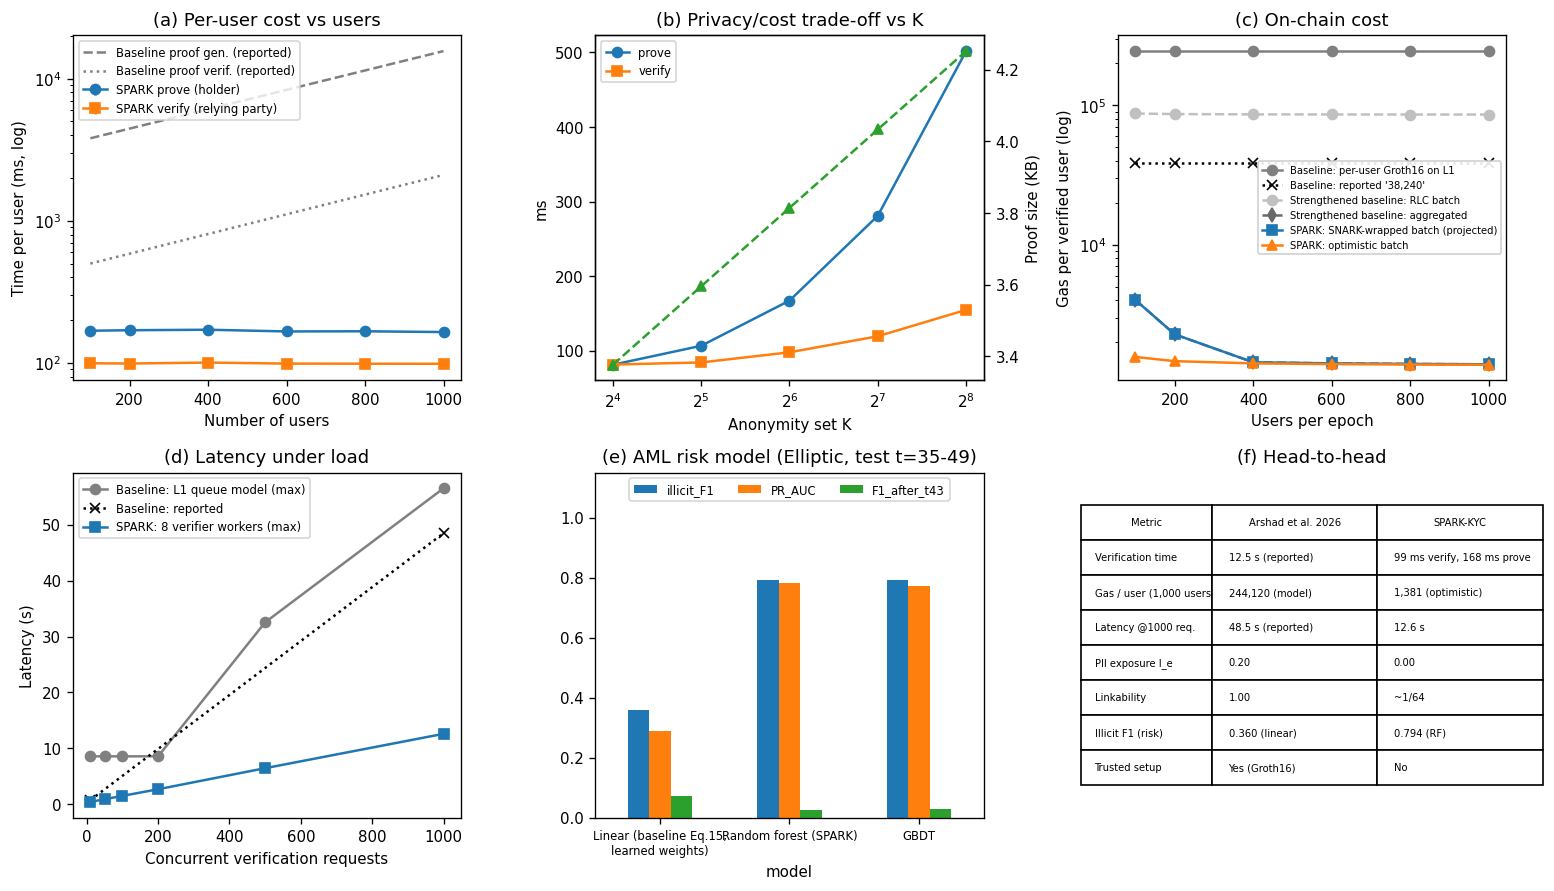

                  Metric Arshad et al. 2026                  SPARK-KYC
       Verification time  12.5 s (reported) 99 ms verify, 168 ms prove
Gas / user (1,000 users)    244,120 (model)         1,381 (optimistic)
      Latency @1000 req.  48.5 s (reported)                     12.6 s
        PII exposure I_e               0.20                       0.00
             Linkability               1.00                      ~1/64
       Illicit F1 (risk)     0.360 (linear)                 0.794 (RF)
           Trusted setup      Yes (Groth16)                         No


In [13]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 120, "font.size": 9})
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))

a = ax[0, 0]
a.errorbar(res_N.users, res_N.prove_ms, yerr=res_N.prove_sd, marker="o", label="SPARK prove (holder)")
a.errorbar(res_N.users, res_N.verify_ms, yerr=res_N.verify_sd, marker="s", label="SPARK verify (relying party)")
a.plot([100, 1000], [3800, 15600], "--", c="gray", label="Baseline proof gen. (reported)")
a.plot([100, 1000], [500, 2100], ":", c="gray", label="Baseline proof verif. (reported)")
a.set_yscale("log"); a.set_xlabel("Number of users"); a.set_ylabel("Time per user (ms, log)"); a.set_title("(a) Per-user cost vs users"); a.legend(fontsize=7)

a = ax[0, 1]
a.plot(res_K.K, res_K.prove_ms, "o-", label="prove"); a.plot(res_K.K, res_K.verify_ms, "s-", label="verify")
a2 = a.twinx(); a2.plot(res_K.K, res_K.proof_bytes / 1024, "^--", c="C2", label="proof size (KB)"); a2.set_ylabel("Proof size (KB)")
a.set_xscale("log", base=2); a.set_xlabel("Anonymity set K"); a.set_ylabel("ms"); a.set_title("(b) Privacy/cost trade-off vs K"); a.legend(loc="upper left", fontsize=7)

a = ax[0, 2]
a.plot(res_G.users, res_G.baseline_groth16_L1_modelled, "o-", c="gray", label="Baseline: per-user Groth16 on L1")
a.plot(res_G.users, res_G.baseline_reported_by_authors, "x:", c="k", label="Baseline: reported '38,240'")
a.plot(res_G.users, res_G.baseline_groth16_RLC_batch, "o--", c="silver", label="Strengthened baseline: RLC batch")
a.plot(res_G.users, res_G.baseline_groth16_aggregated, "d--", c="dimgray", label="Strengthened baseline: aggregated")
a.plot(res_G.users, res_G.spark_snark_wrapped_projected, "s-", label="SPARK: SNARK-wrapped batch (projected)")
a.plot(res_G.users, res_G.spark_optimistic, "^-", label="SPARK: optimistic batch")
a.set_yscale("log"); a.set_xlabel("Users per epoch"); a.set_ylabel("Gas per verified user (log)"); a.set_title("(c) On-chain cost"); a.legend(fontsize=6, loc="center right", framealpha=0.9)

a = ax[1, 0]
a.plot(res_L.concurrent, res_L.baseline_L1_max_s, "o-", c="gray", label="Baseline: L1 queue model (max)")
a.plot([10, 1000], [0.7, 48.5], "x:", c="k", label="Baseline: reported")
a.plot(res_L.concurrent, res_L.spark_max_s, "s-", label=f"SPARK: {CFG['verifier_workers']} verifier workers (max)")
a.set_xlabel("Concurrent verification requests"); a.set_ylabel("Latency (s)"); a.set_title("(d) Latency under load"); a.legend(fontsize=7)

a = ax[1, 1]
rs = risk_df.groupby("model")[["illicit_F1", "PR_AUC", "F1_after_t43"]].mean().loc[["linear", "rf", "gbdt"]]
rs.plot.bar(ax=a, rot=0); a.set_title("(e) AML risk model (Elliptic, test t=35-49)"); a.set_ylim(0, 1.15); a.legend(fontsize=7, ncol=3, loc="upper center")
a.set_xticklabels(["Linear (baseline Eq.15,\nlearned weights)", "Random forest" + (" (SPARK)" if SPARK_MODEL == "rf" else ""), "GBDT" + (" (SPARK)" if SPARK_MODEL == "gbdt" else "")], fontsize=7)

a = ax[1, 2]; a.axis("off")
summary = pd.DataFrame([
    ["Verification time", "12.5 s (reported)", f"{res_N.verify_ms.mean():.0f} ms verify, {res_N.prove_ms.mean():.0f} ms prove"],
    ["Gas / user (1,000 users)", f"{gas_baseline_groth16():,} (model)", f"{res_G.spark_optimistic.iloc[-1]:,.0f} (optimistic)"],
    ["Latency @1000 req.", "48.5 s (reported)", f"{res_L.spark_max_s.iloc[-1]:.1f} s"],
    ["PII exposure I_e", "0.20", "0.00"],
    ["Linkability", "1.00", f"~1/{CFG['K']}"],
    ["Illicit F1 (risk)", "%.3f (linear)" % rs.loc["linear", "illicit_F1"], "%.3f (%s)" % (rs.loc[SPARK_MODEL, "illicit_F1"], SPARK_MODEL.upper())],
    ["Trusted setup", "Yes (Groth16)", "No"],
], columns=["Metric", "Arshad et al. 2026", "SPARK-KYC"])
tb = a.table(cellText=summary.values, colLabels=summary.columns, loc="center", cellLoc="left", colWidths=[0.30, 0.38, 0.38]); tb.auto_set_font_size(False); tb.set_fontsize(6); tb.scale(1.12, 1.6)
a.set_title("(f) Head-to-head")
plt.tight_layout(); plt.savefig("results/spark_kyc_results.png", dpi=300); plt.show()
summary.to_csv("results/summary_head_to_head.csv", index=False)
print(summary.to_string(index=False))
if not REAL_DATA: print("\n!! Risk results above used the SYNTHETIC stand-in because the Elliptic download failed. Re-run with internet.")